/home/pyc2/miniconda3/envs/clickview/lib/python3.10/site-packages/anndata/_core/anndata.py:1138: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
/home/pyc2/miniconda3/envs/clickview/lib/python3.10/site-packages/legacy_api_wrap/__init__.py:88: FutureWarning: `scale` is deprecated, use `density_norm` instead
  return fn(*args_all, **kw)
/home/pyc2/miniconda3/envs/clickview/lib/python3.10/site-packages/scanpy/plotting/_anndata.py:961: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/home/pyc2/miniconda3/envs/clickview/lib/python3.10/site-packages/anndata/_core/anndata.py:1138: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
/home/pyc2/miniconda3/envs/clickview/lib/python3.10/site-packages/legacy_api_wrap/__

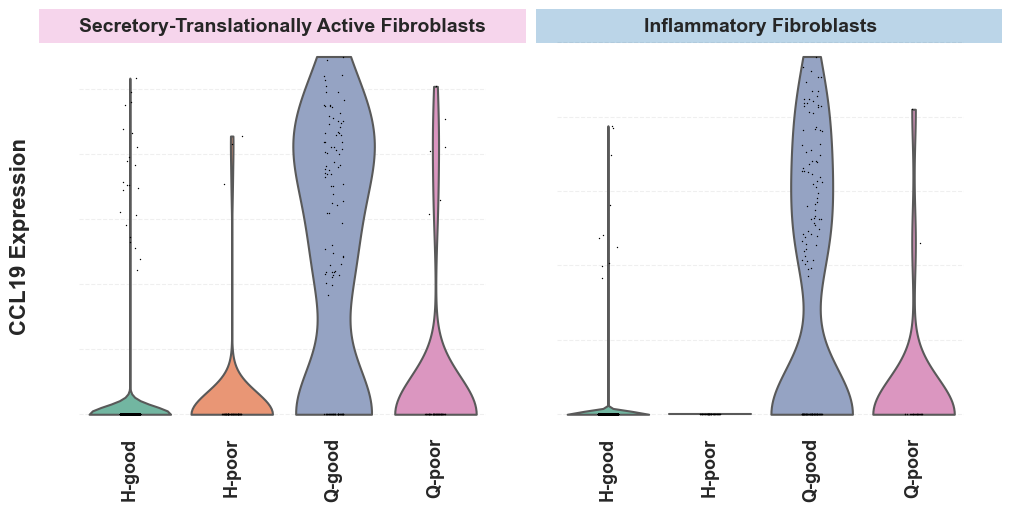

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.patches as patches
import scanpy as sc

padata = sc.read("./h5ad/adata_fibroblast.h5ad")

batch2effect = {
    "H-nS01":"H-poor",
    "Q-nS01":"Q-poor",
    "Q-nS02":"Q-poor",
    "H-nS08":"H-good",
    "Q-nS03":"Q-good",
    "Q-nS04":"Q-good",
    "H-nS03":"H-good",
    "H-nS06":"H-good",
    "H-nS07":"H-good",
    "H-nS09":"H-poor",
    "H-nS10":"H-poor"
}
padata.obs["effect"]=[batch2effect[b] for b in padata.obs["batch"]]

sc.pp.normalize_total(padata, target_sum=1e6)
sc.pp.log1p(padata)

# 设置美观的全局样式
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")

# 定义颜色
PINK_COLOR = '#e377c2'  # 粉色
BLUE_COLOR = '#1f77b4'  # 蓝色

# 创建包含两个子图的画布
fig, axes = plt.subplots(1, 2, figsize=(10, 5), constrained_layout=True)

# 设置统一的美观参数
violin_params = {
    'linewidth': 1.5,
    'scale': 'width',
    'cut': 0,
    'palette': 'Set2'
}

# 第一个图：Secretory-Translationally Active Fibroblasts
sc.pl.violin(
    padata[padata.obs["celltype"]=='Secretory-Translationally Active Fibroblast'],
    keys="CCL19",
    rotation=90,
    show=False,
    groupby="effect",
    ax=axes[0],
    **violin_params
)

# 先设置标题（但不显示，只是为了获取位置）
title0 = axes[0].set_title('Secretory-Translationally Active Fibroblasts', 
                          fontsize=14, fontweight='bold', pad=5)
# 绘制标题（使其可见）
title0.set_visible(True)

# 获取标题的边界框（在图形坐标中）
renderer = fig.canvas.get_renderer()
bbox = title0.get_window_extent(renderer=renderer)

# 转换到数据坐标
bbox_data = bbox.transformed(axes[0].transAxes.inverted())

# 计算一个更大的矩形来环绕标题（添加一些边距）
margin = 0.02  # 边距
rect_x0 = bbox_data.x0 - margin
rect_y0 = bbox_data.y0 - margin
rect_width = bbox_data.width + 2 * margin
rect_height = bbox_data.height + 2 * margin

# 添加环绕标题的粉色背景矩形
rect0 = patches.Rectangle(
    (rect_x0, rect_y0), 
    rect_width, 
    rect_height,
    transform=axes[0].transAxes,
    facecolor=PINK_COLOR,
    alpha=0.3,
    edgecolor='none',
    zorder=2,  # 在标题下面
    clip_on=False  # 允许绘制在坐标轴之外
)
axes[0].add_patch(rect0)

# 确保标题在最上层
title0.set_zorder(3)

axes[0].set_ylabel('CCL19 Expression', fontsize=16, fontweight='bold')
axes[0].yaxis.set_label_coords(-0.12, 0.5)
axes[0].tick_params(axis='y', which='both', left=False, labelleft=False)

# 第二个图：Inflammatory Fibroblasts
sc.pl.violin(
    padata[padata.obs["celltype"]=='Inflammatory Fibroblast'],
    keys="CCL19",
    rotation=90,
    show=False,
    groupby="effect",
    ax=axes[1],
    **violin_params
)

# 设置标题
title1 = axes[1].set_title('Inflammatory Fibroblasts', 
                          fontsize=14, fontweight='bold', pad=5)
title1.set_visible(True)

# 获取标题的边界框
bbox = title1.get_window_extent(renderer=renderer)
bbox_data = bbox.transformed(axes[1].transAxes.inverted())

# 计算环绕标题的矩形
rect_x0 = bbox_data.x0 - margin - 0.2
rect_y0 = bbox_data.y0 - margin
rect_width = bbox_data.width + 24 * margin
rect_height = bbox_data.height + 2 * margin

# 添加环绕标题的蓝色背景矩形
rect1 = patches.Rectangle(
    (rect_x0, rect_y0), 
    rect_width, 
    rect_height,
    transform=axes[1].transAxes,
    facecolor=BLUE_COLOR,
    alpha=0.3,
    edgecolor='none',
    zorder=2,
    clip_on=False
)
axes[1].add_patch(rect1)

# 确保标题在最上层
title1.set_zorder(3)

axes[1].set_ylabel('')
axes[1].tick_params(axis='y', which='both', left=False, labelleft=False)

# 去掉所有边框
for ax in axes:
    ax.grid(True, linestyle='--', alpha=0.3, axis='y')
    for spine in ax.spines.values():
        spine.set_visible(False)

# 遍历所有子图
for ax in axes:
    # 遍历子图中所有的文字对象
    for label in ax.get_xticklabels():
        # 将 groupby 标签加粗
        label.set_fontweight('bold')
        label.set_size(13)

# 确保你的图形更新
plt.draw()
plt.show()